## Descriptive Statistics

In [1]:
import pandas as pd

# load data
df = pd.read_csv("TMDB_movie_dataset_v11.csv")

# numeric columns
numeric_cols = ["budget", "revenue", "runtime", "vote_average"]

# mean, median, std
stats_df = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "median": df[numeric_cols].median(),
    "std": df[numeric_cols].std()
})

stats_df

,mean,median,std
budget,233546.840854,0.0,5.121386e+06
revenue,616978.195193,0.0,1.965394e+07
runtime,43.698611,15.0,6.055839e+01
vote_average,1.535650,0.0,2.846254e+00


## Data Cleanup Overview

In [2]:
# count missing values
missing_values = df[numeric_cols].isna().sum()

# count bad values
negative_runtime = (df["runtime"] < 0).sum()
non_positive_revenue = (df["revenue"] <= 0).sum()
non_positive_budget = (df["budget"] <= 0).sum()

# put the counts in a table
anomalies_df = pd.DataFrame({
    "metric": ["Missing values (NaN)", "runtime < 0", "revenue <= 0", "budget <= 0"],
    "count": [
        missing_values.sum(),
        negative_runtime,
        non_positive_revenue,
        non_positive_budget
    ]
})

anomalies_df

,metric,count
0,Missing values (NaN),0
1,runtime < 0,1
2,revenue <= 0,1415663
3,budget <= 0,1356977


In [ ]:
# missing values per column
missing_values

budget          0
revenue         0
runtime         0
vote_average    0
dtype: int64

## Discussion

### What the descriptive statistics show

When I look at the statistics, I can see a big difference between the mean and the median for `budget` and `revenue`. The mean is much bigger than the median. This means the data is not symmetric, it is skewed to the right. The reason is that there are some very expensive blockbuster movies with very high budget and revenue. These few big movies pull the mean up, but the median stays low, so the median describe a typical movie better. The big standard deviation also shows that the values are very spread out and there are a lot of outliers.

For `runtime` and `vote_average` the mean and the median are close to each other. So these two columns are more symmetric and more stable.

The data quality check also shows some problems. There are missing values, and also rows that do not make sense, for example `budget` and `revenue` equal to zero or negative, and negative `runtime`. Usually these values do not describe a real movie, they only mean that the data is missing (saved as 0 or as a negative number). If I keep them, they will break the plots and the statistics later, especially the histograms and the scatter plots.

So before I make any visualization, I need to clean the data first: remove or fix the missing values, and drop the rows where `budget` or `revenue` is not positive and where `runtime` is negative, because these values give no real information and they are just artifacts from how the data was collected.

## Data Cleanup & Transformation

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# plot style
sns.set_theme(style="whitegrid", palette="deep")

# load raw data
df = pd.read_csv("TMDB_movie_dataset_v11.csv")
print(f"Original size: {len(df):,} rows")

# keep only real movies (drop fake budgets, short clips and unrated films)
df_clean = df.query(
    "budget > 10000 and revenue > 10000 and runtime >= 40 "
    "and vote_average > 0 and vote_count >= 10"
).copy()
print(f"After strict filtering: {len(df_clean):,} rows "
      f"({len(df_clean) / len(df):.2%} of the original volume)")

# add profit and roi
df_clean["profit"] = df_clean["revenue"] - df_clean["budget"]
df_clean["roi"] = df_clean["revenue"] / df_clean["budget"]

# get release year from the date
df_clean["release_date"] = pd.to_datetime(df_clean["release_date"], errors="coerce")
df_clean["release_year"] = df_clean["release_date"].dt.year.astype("Int64")

# check the result
df_clean[["budget", "revenue", "runtime", "profit", "roi", "release_year"]].describe()

Original size: 1,440,254 rows
After strict filtering: 8,743 rows (0.61% of the original volume)


,budget,revenue,runtime,profit,roi,release_year
count,8.743000e+03,8.743000e+03,8743.000000,8.743000e+03,8743.000000,8743.0
mean,2.688721e+07,7.577031e+07,109.892028,4.888309e+07,6.034311,2000.649434
std,3.952038e+07,1.647617e+08,21.781291,1.382902e+08,65.687802,18.279173
min,1.100000e+04,1.001800e+04,41.000000,-1.995460e+08,0.000715,1915.0
25%,4.000000e+06,4.073756e+06,95.000000,-2.177431e+06,0.683676,1994.0
50%,1.250000e+07,1.887992e+07,105.000000,5.616129e+06,1.875933,2006.0
75%,3.100000e+07,7.142899e+07,120.000000,4.249192e+07,3.964381,2013.0
max,4.600000e+08,2.923706e+09,339.000000,2.686706e+09,4143.984983,2023.0


## Simple Plots

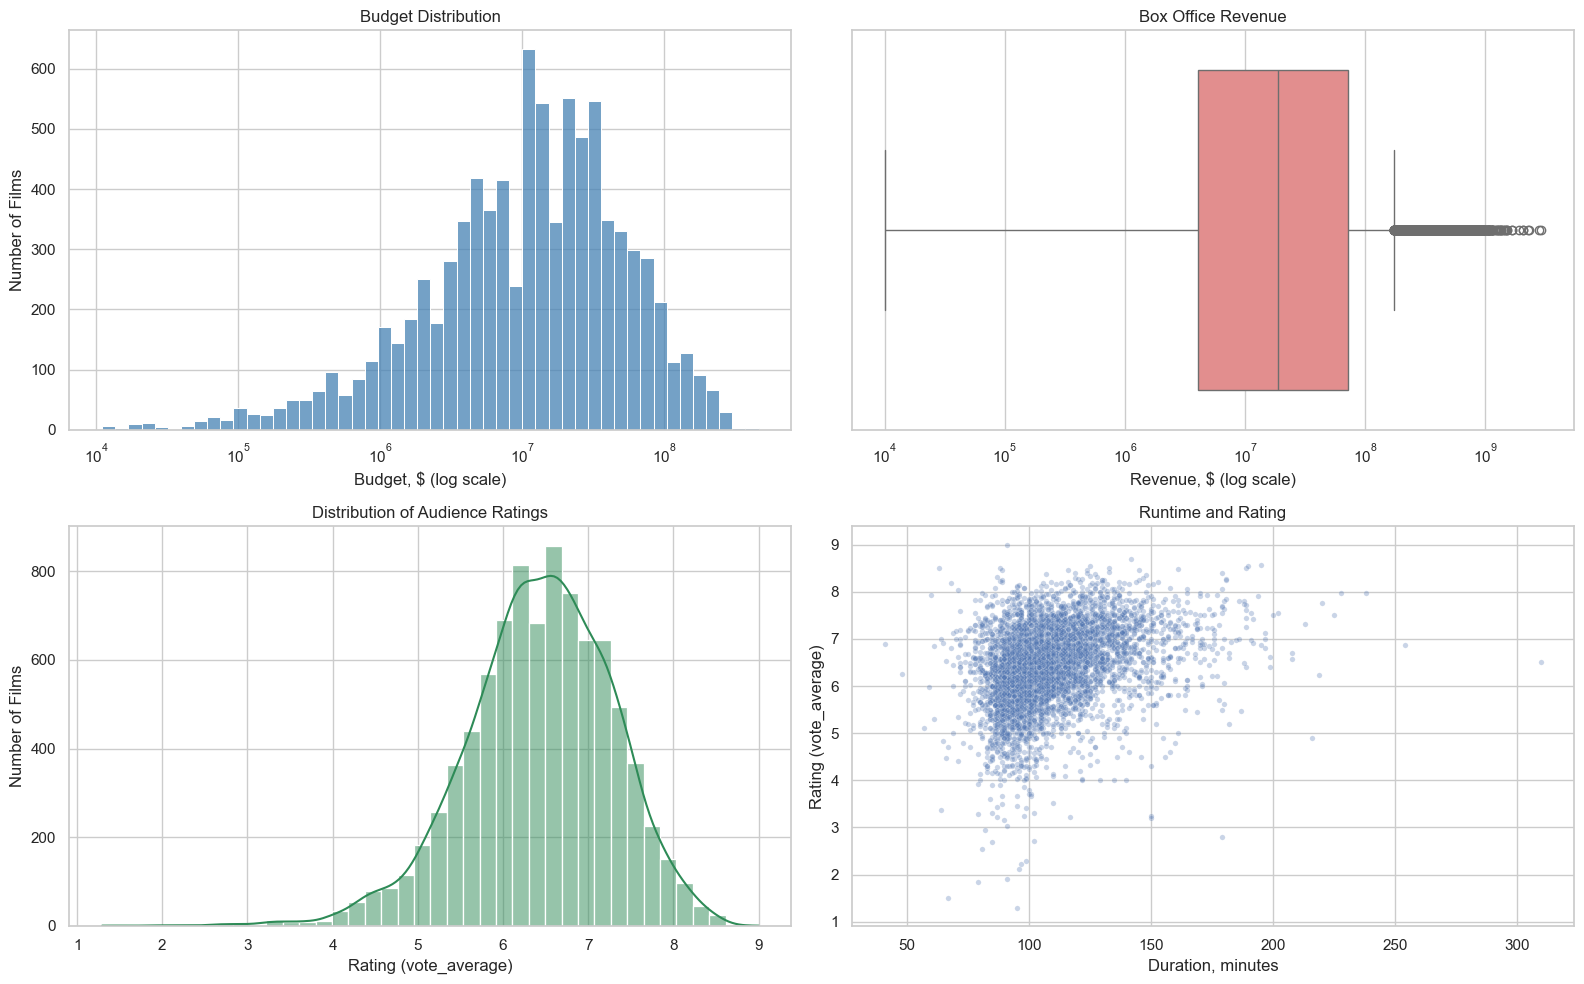

In [5]:
# 4 basic plots
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# budget histogram (log scale)
sns.histplot(df_clean["budget"], bins=50, log_scale=True, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Budget Distribution")
axes[0, 0].set_xlabel("Budget, $ (log scale)")
axes[0, 0].set_ylabel("Number of Films")

# revenue boxplot
sns.boxplot(x=df_clean["revenue"], color="lightcoral", ax=axes[0, 1])
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Box Office Revenue")
axes[0, 1].set_xlabel("Revenue, $ (log scale)")

# rating histogram
sns.histplot(df_clean["vote_average"], bins=40, kde=True, color="seagreen", ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Audience Ratings")
axes[1, 0].set_xlabel("Rating (vote_average)")
axes[1, 0].set_ylabel("Number of Films")

# runtime vs rating (sample of points)
sample = df_clean.sample(n=min(len(df_clean), 5000), random_state=42)
sns.scatterplot(data=sample, x="runtime", y="vote_average", alpha=0.3, s=15, ax=axes[1, 1])
axes[1, 1].set_title("Runtime and Rating")
axes[1, 1].set_xlabel("Duration, minutes")
axes[1, 1].set_ylabel("Rating (vote_average)")

plt.tight_layout()
plt.show()

## Detailed Overview

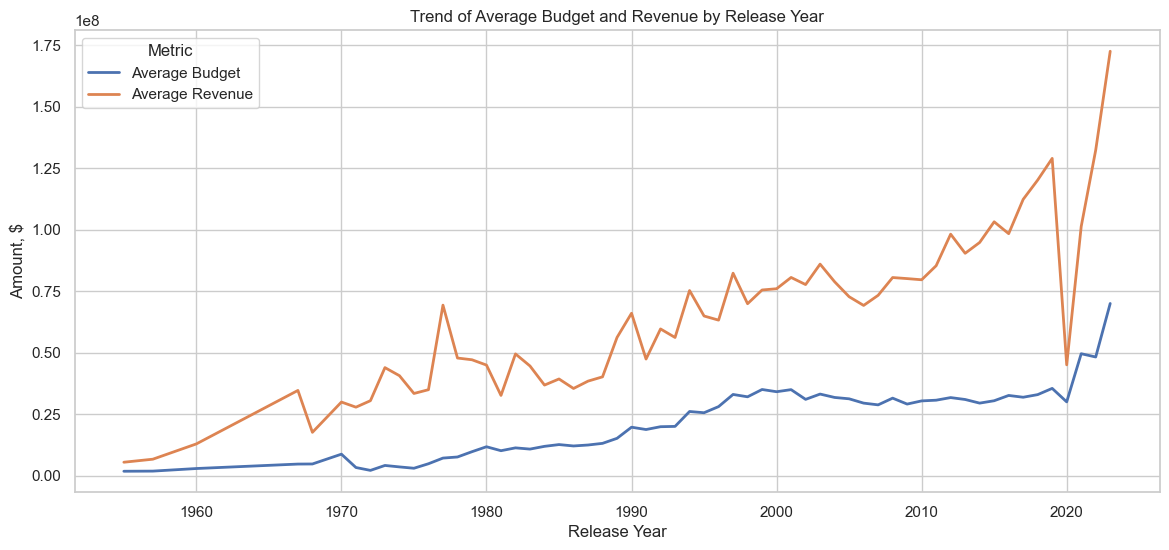

In [6]:
# average budget and revenue per year (only years with 20+ movies)
yearly = (
    df_clean
    .dropna(subset=["release_year"])
    .groupby("release_year")
    .agg(mean_budget=("budget", "mean"),
         mean_revenue=("revenue", "mean"),
         n_movies=("id", "count"))
    .query("n_movies >= 20")
    .reset_index()
)

plt.figure(figsize=(14, 6))
sns.lineplot(data=yearly, x="release_year", y="mean_budget", label="Average Budget", linewidth=2)
sns.lineplot(data=yearly, x="release_year", y="mean_revenue", label="Average Revenue", linewidth=2)
plt.title("Trend of Average Budget and Revenue by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Amount, $")
plt.legend(title="Metric")
plt.show()

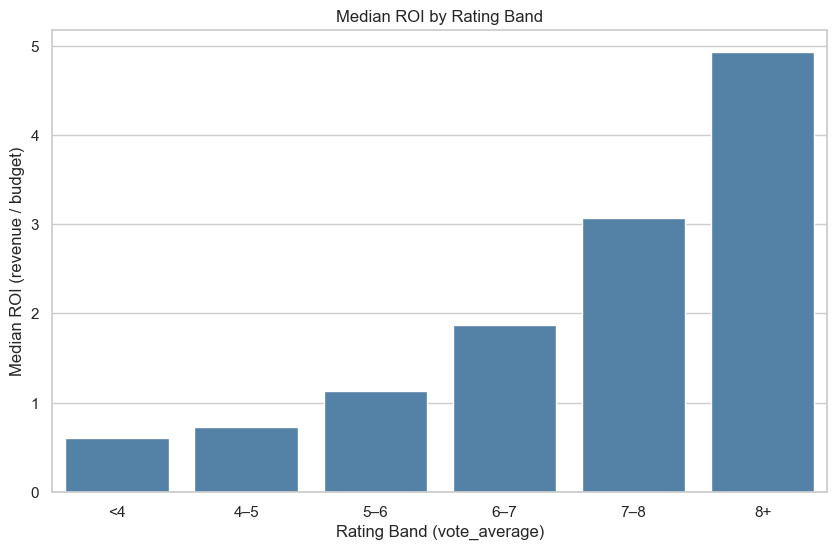

In [7]:
# median ROI by rating group
rating_bins = [0, 4, 5, 6, 7, 8, 10]
rating_labels = ["<4", "4-5", "5-6", "6-7", "7-8", "8+"]
df_clean["rating_band"] = pd.cut(df_clean["vote_average"], bins=rating_bins, labels=rating_labels)

# median is used because ROI has big outliers
roi_by_rating = (
    df_clean
    .groupby("rating_band", observed=True)["roi"]
    .median()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=roi_by_rating, x="rating_band", y="roi", color="steelblue")
plt.title("Median ROI by Rating Band")
plt.xlabel("Rating Band (vote_average)")
plt.ylabel("Median ROI (revenue / budget)")
plt.show()

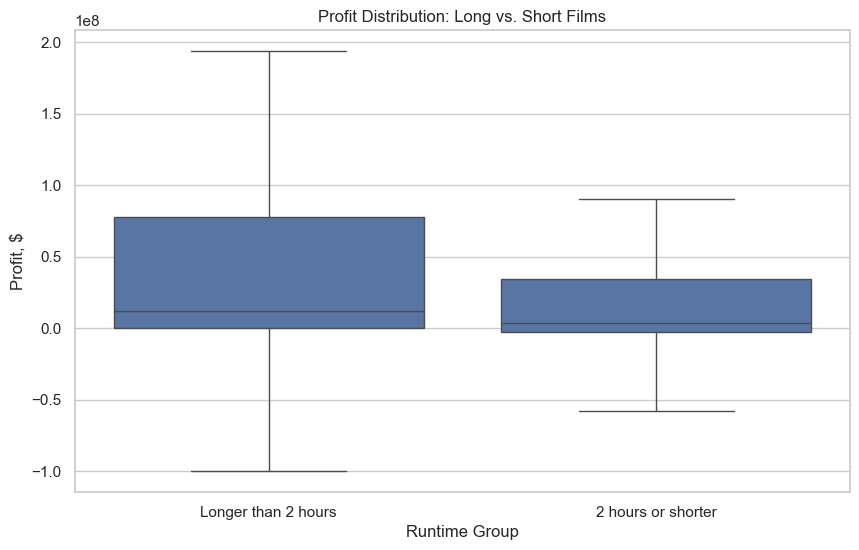

In [8]:
# split movies into long and short (2 hours)
df_clean["length_group"] = (df_clean["runtime"] > 120).map(
    {True: "Longer than 2 hours", False: "2 hours or shorter"}
)

plt.figure(figsize=(10, 6))
# hide outliers so the boxes are readable
sns.boxplot(data=df_clean, x="length_group", y="profit", showfliers=False)
plt.title("Profit Distribution: Long vs. Short Films")
plt.xlabel("Runtime Group")
plt.ylabel("Profit, $")
plt.show()

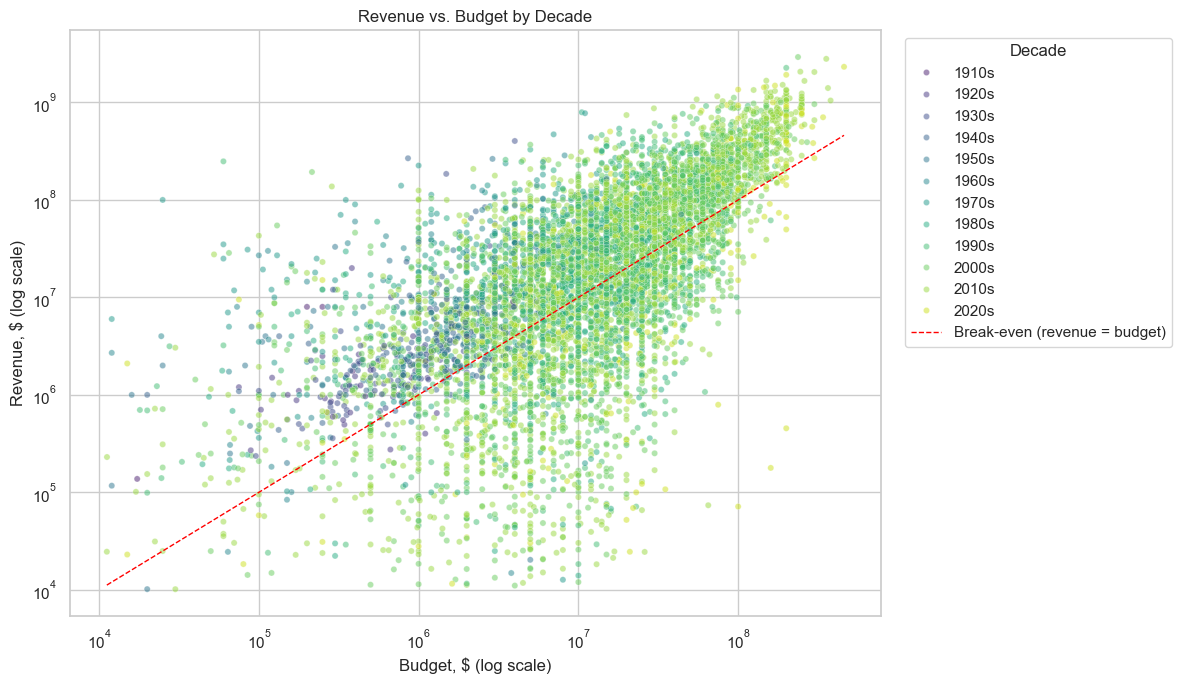

In [9]:
# revenue vs budget by decade
plot_df = df_clean.dropna(subset=["release_year"]).copy()
plot_df["decade"] = ((plot_df["release_year"] // 10) * 10).astype(int).astype(str) + "s"

# sample for readability
sample = plot_df.sample(n=min(len(plot_df), 8000), random_state=42)

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=sample, x="budget", y="revenue",
    hue="decade", hue_order=sorted(sample["decade"].unique()),
    palette="viridis", alpha=0.5, s=20
)
plt.xscale("log")
plt.yscale("log")

# break-even line (revenue = budget)
lims = [sample["budget"].min(), sample["budget"].max()]
plt.plot(lims, lims, color="red", linestyle="--", linewidth=1,
         label="Break-even (revenue = budget)")

plt.title("Revenue vs. Budget by Decade")
plt.xlabel("Budget, $ (log scale)")
plt.ylabel("Revenue, $ (log scale)")
plt.legend(title="Decade", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Discussion: cleaning the data in two steps and looking at the plots

### 1. First cleaning step and its problems

The first data quality check showed that about 1.4 million rows have zero in the `budget` and `revenue` columns, and the `runtime` column has zero and negative values. These values are not a real economic fact, they only mean that the data is missing in the TMDB database. So the first step was a simple filter: `budget > 0 AND revenue > 0 AND runtime > 0`. But after this filter the data was still around 14,800 rows, and the `describe()` showed that there were still `budget` and `revenue` equal to $1 and `runtime` equal to 1 minute.

### 2. A second layer of "dirt" that I found with the plots

When I plotted the result of the first step, I understood that dropping only the zeros was not enough. The data had a second, more hidden layer of bad values. I could not see it in the summary statistics, but it was very clear in the plots:

* **Fake budgets.** The budget histogram (log scale) showed strange spikes around $1-$10. These values are positive, so they pass the first filter, but they are not real budgets. They are just "placeholders" that somebody put in the database when there was no real money information. They make the ROI (`revenue / budget`) crazy high, like millions of times, because the budget is almost zero.
* **Too short runtimes.** The `runtime` column had many rows with 1 to 5 minutes. These are trailers, teasers and music videos, not real movies. If I mix them with real movies, every analysis about duration becomes wrong.
* **Movies with no votes.** A lot of rows have `vote_average = 0.0`. This is not a real score of zero, it only means that nobody voted for the movie. If I keep them in the rating analysis, they make a fake spike at zero.

### 3. Second, stronger cleaning step

To keep only real commercial movies with good data, I used a stronger filter: `budget > 10000 AND revenue > 10000 AND runtime >= 40 AND vote_average > 0 AND vote_count >= 10`. Every condition removes one type of bad value: the $10,000 limits remove the fake budgets and revenues; `runtime >= 40` removes the short videos and keeps normal movies; `vote_average > 0` together with `vote_count >= 10` makes sure the rating comes from enough votes and not from one random person. This step makes the dataset much smaller, but much more reliable.

After that I added two new financial columns. **Profit** (`profit = revenue - budget`) shows the absolute money result in dollars, and **ROI** (`roi = revenue / budget`) shows how efficient the investment is. They are useful together: a big blockbuster can have a huge profit but a small ROI, and a cheap movie can have a small profit but a very big ROI. I also took the release year `release_year` from `release_date` with `pd.to_datetime(errors="coerce")` to study the trends over time.

### 4. Simple plots

I show the money columns on a log scale, because their values go over many orders of magnitude. After the second cleaning step the budget histogram does not have the fake spikes near $1 anymore, and the rating distribution loses the fake spike at zero and looks like a normal bell shape around 6-7 points. The revenue boxplot shows the median, the middle 50% and the outliers in a compact way.

### 5. Detailed comparisons

**(a) Trend over the years** shows the effect of inflation and the move of the industry to big franchise movies; both lines grow, and the revenue is usually higher than the budget. **(b) ROI by rating band** uses the median, because it is more stable against the extreme ROI outliers. **(c) Profit of long vs short movies** looks at the connection between duration, budget and absolute profit. **(d) Budget vs revenue by decade** on a double log scale shows a positive relation between the two columns and how the points move up and to the right with time; the dashed line is the break-even line and it separates the movies that made money from the ones that lost money.

### 6. Final notes

The two-step cleaning gave me a reliable dataset for the analysis. But I have to mention one limit: after the strong filter, the data keeps mostly big movies that publish their financial information, so there is some survivorship bias. The conclusions work well for commercial movies with public financial data, but not for all the cinema in general.

## Hypothesis checking

I test two hypotheses on the cleaned data.

**Hypothesis 1 (ROI and budget size).** Blockbusters with a budget over $100 million have a lower *median* ROI than mid-budget movies ($10-100 million). The idea is simple: very big production and marketing costs grow faster than the extra money from the box office, so a bigger budget gives more absolute profit but less efficiency per dollar.

**Hypothesis 2 (rating and popularity by language).** For English movies (`original_language == 'en'`), the Pearson correlation between the rating (`vote_average`) and the popularity (`popularity`) is higher than for movies in other languages. The idea is that English movies are made for a big global audience, where quality and popularity are more connected; for other languages, popularity often depends more on local or festival reasons, which are less connected to the average rating.

In [18]:
# H1: ROI of blockbusters vs mid-budget movies
blockbusters = df_clean[df_clean["budget"] > 100_000_000]
mid_budget = df_clean[(df_clean["budget"] >= 10_000_000) & (df_clean["budget"] <= 100_000_000)]

roi_blockbusters = blockbusters["roi"].median()
roi_mid_budget = mid_budget["roi"].median()

print("=" * 64)
print("HYPOTHESIS 1: Median ROI by budget category")
print("=" * 64)
print(f"Blockbusters (budget > $100M):  n = {len(blockbusters):>5,} | "
      f"median ROI = {roi_blockbusters:.2f}")
print(f"Mid-budget ($10-100M):          n = {len(mid_budget):>5,} | "
      f"median ROI = {roi_mid_budget:.2f}")

if roi_blockbusters < roi_mid_budget:
    print("\nCONCLUSION: Hypothesis CONFIRMED - blockbusters have a lower median ROI,")
    print("            which is consistent with diminishing returns to budget scale.")
else:
    print("\nCONCLUSION: Hypothesis REJECTED - blockbusters' median ROI is not lower.")

ГИПОТЕЗА 1: Медианный ROI по бюджетным категориям
Блокбастеры (бюджет > $100 млн):  n =   444 | медианный ROI = 2.78
Среднебюджетное ($10-100 млн):    n = 4,570 | медианный ROI = 1.60

ВЫВОД: Гипотеза ОПРОВЕРГАЕТСЯ - медианный ROI блокбастеров не ниже.


In [19]:
# H2: rating-popularity correlation by language
en_films = df_clean[df_clean["original_language"] == "en"]
other_films = df_clean[df_clean["original_language"] != "en"]

# .corr() is Pearson by default
corr_en = en_films["vote_average"].corr(en_films["popularity"])
corr_other = other_films["vote_average"].corr(other_films["popularity"])

print("=" * 64)
print("HYPOTHESIS 2: Pearson correlation (vote_average ~ popularity)")
print("=" * 64)
print(f"English (en):      n = {len(en_films):>5,} | r = {corr_en:.4f}")
print(f"Other languages:   n = {len(other_films):>5,} | r = {corr_other:.4f}")

if corr_en > corr_other:
    print("\nCONCLUSION: Hypothesis CONFIRMED - for English-language films, the relationship")
    print("            between rating and popularity is stronger than for the rest.")
else:
    print("\nCONCLUSION: Hypothesis REJECTED - the correlation for English-language films is not higher.")

ГИПОТЕЗА 2: Корреляция Пирсона (vote_average ~ popularity)
Английский язык (en):  n = 7,081 | r = 0.1384
Другие языки:          n = 1,662 | r = 0.2461

ВЫВОД: Гипотеза ОПРОВЕРГАЕТСЯ - корреляция для англоязычных не выше.


## Export of the Cleaned Dataset

In [10]:
# save cleaned data for the API
df_clean.to_csv("tmdb_cleaned_for_api.csv", index=False)
print(f"Dataset saved: tmdb_cleaned_for_api.csv "
      f"({len(df_clean):,} rows, {df_clean.shape[1]} columns)")

Dataset saved: tmdb_cleaned_for_api.csv (8,743 rows, 29 columns)
